In [1]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([
    [1, 20],
    [1, 60],
    [2, 40],
    [2, 80],
    [3, 20],
    [3, 100],
    [4, 60],
    [4, 120],
    [5, 40],
    [5, 100],
    [6, 80],
    [6, 120],
], dtype=float)

y = np.array([50, 54, 58, 62, 61, 69, 69, 75, 71, 77, 76, 80])

print(X.shape, y.shape)

(12, 2) (12,)


In [2]:
def scale_features(X):
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    return (X - mean) / std, mean, std

X_scaled, mean, std = scale_features(X)

print("放缩前的标准差", std)
print("放缩后的标准差", X_scaled.std(axis=0))

放缩前的标准差 [ 1.70782513 34.15650255]
放缩后的标准差 [1. 1.]


In [3]:
def train(X, y, alpha=0.1, steps=300):
    m, n = X.shape
    w = np.zeros(n)
    b = 0.0
    history = []

    for step in range(steps + 1):
        prediction = X @ w + b
        error = prediction - y
        history.append(np.mean(error ** 2) / 2)

        if step == steps:
            break

        dw = (X.T @ error) / m
        db = np.mean(error)

        w = w - alpha * dw
        b = b - alpha * db

    return w, b, history

w, b, history = train(X_scaled, y)
print("初始成本", history[0])
print("最终成本", history[-1])

初始成本 2276.5833333333335
最终成本 0.8915865088175305


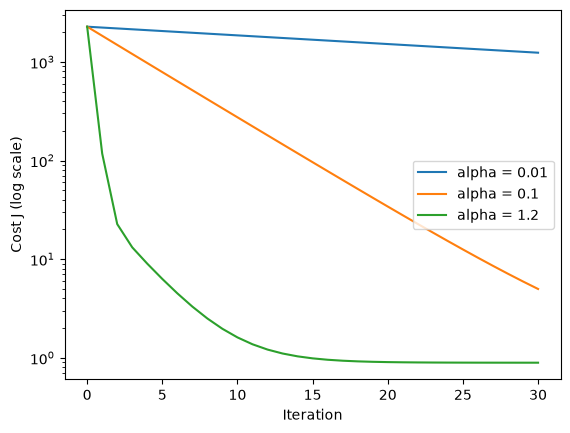

In [4]:
for alpha in (0.01, 0.1, 1.2):
    _, _, costs = train(X_scaled, y, alpha=alpha, steps=30)
    plt.semilogy(costs, label=f"alpha = {alpha}")

plt.xlabel("Iteration")
plt.ylabel("Cost J (log scale)")
plt.legend()
plt.show()

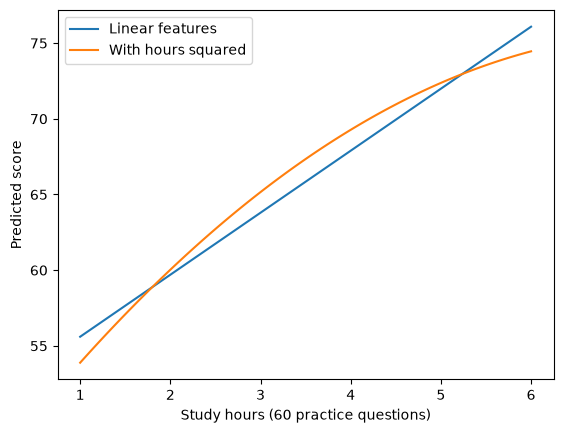

In [5]:
X_poly = np.column_stack([X, X[:, 0] ** 2])
X_poly_scaled, poly_mean, poly_std = scale_features(X_poly)

w_poly, b_poly, poly_history = train(X_poly_scaled, y, steps=2000)

hours = np.linspace(1, 6, 100)
questions = np.full_like(hours, 60)

line_inputs = np.column_stack([hours, questions])
poly_inputs = np.column_stack([hours, questions, hours ** 2])

linear_scores = ((line_inputs - mean) / std) @ w + b
poly_scores = ((poly_inputs - poly_mean) / poly_std) @ w_poly + b_poly

plt.plot(hours, linear_scores, label="Linear features")
plt.plot(hours, poly_scores, label="With hours squared")
plt.xlabel("Study hours (60 practice questions)")
plt.ylabel("Predicted score")
plt.legend()
plt.show()